In [1]:
import h2py
import demes
import demesdraw
import matplotlib.pyplot as plt
import matplotlib as mpl
import msprime
import numpy as np
import pickle
import pandas


mpl.rc("xtick", labelsize=7)
mpl.rc("ytick", labelsize=7)
mpl.rc("font", size=8)
mpl.rc("axes", labelsize=8)
mpl.rc("axes", titlesize=8)
mpl.rc("legend", fontsize=7)
mpl.rc("axes", titlesize="small")

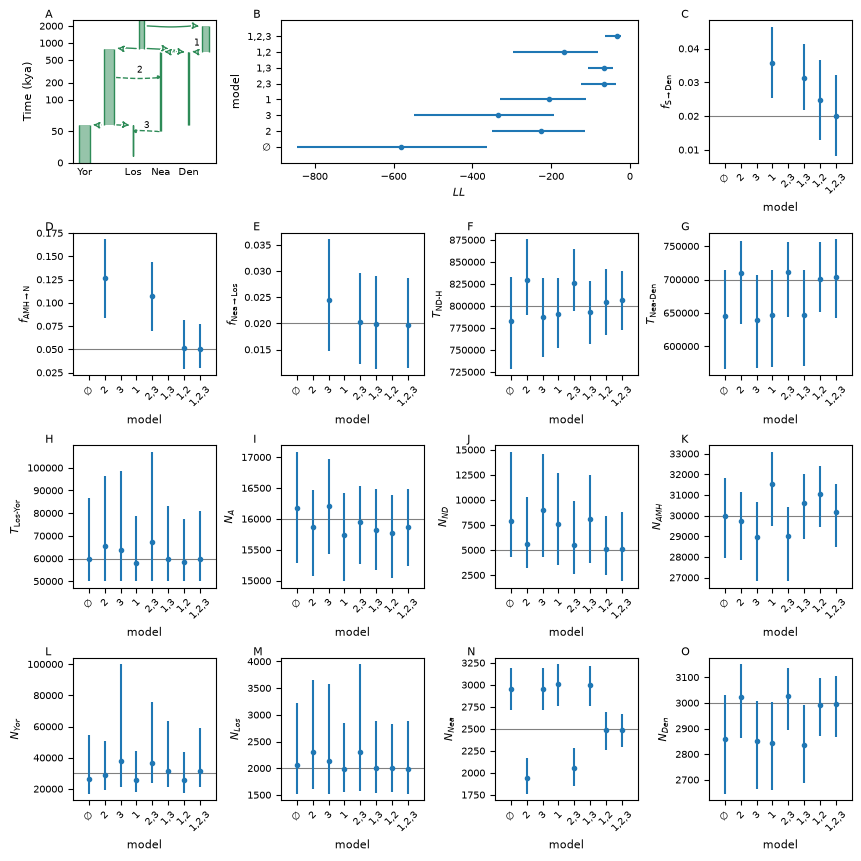

In [3]:
"""
A cleaner figure
"""


path = "results"
graph_file = f"models/model_111.yaml"
graph = demes.load(graph_file)
tbls = {
    "000": pandas.read_csv(f"{path}/fits_model_000.csv"),
    "010": pandas.read_csv(f"{path}/fits_model_010.csv"),  
    "001": pandas.read_csv(f"{path}/fits_model_001.csv"), 
    "100": pandas.read_csv(f"{path}/fits_model_100.csv"),
    "011": pandas.read_csv(f"{path}/fits_model_011.csv"),
    "101": pandas.read_csv(f"{path}/fits_model_101.csv"),
    "110": pandas.read_csv(f"{path}/fits_model_110.csv"),
    "111": pandas.read_csv(f"{path}/fits_model_111.csv"),
}

model_labels = {
    "111": "1,2,3",
    "110": "1,2",
    "101": "1,3",
    "011": "2,3",
    "100": "1",
    "010": "2",
    "001": "3",
    "000": r"$\varnothing$",
}

# figure parameters
colors = mpl.colors.TABLEAU_COLORS
_lw = 1.75


mosaic = "ABBC;DEFG;HIJK;LMNO"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(8.5, 8.5), layout="constrained")


# plot graph    
positions = {
    "Yor": -4e4,
    "Los": 1e5,
    "Nea": 1.8e5,
    "Den": 2.6e5,
    "Sup": 3.1e5,
    "Afr": 3e4, 
    "ND": 2.15e5,
    "Anc": 1.25e5,
}
demesdraw.tubes(graph, ax=axs["A"], colours="seagreen", labels=None, positions=positions)    
axs["A"].spines["top"].set_visible(True)
axs["A"].spines["right"].set_visible(True)
axs["A"].spines["bottom"].set_visible(True)    
axs["A"].set_yscale("symlog", linthresh=1e5)
axs["A"].set_ylabel("Time (kya)")
yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6]
axs["A"].set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
label_me = ["Yor", "Los", "Nea", "Den"]
axs["A"].set_xticks([positions[label] for label in label_me], label_me)
axs["A"].text(2.85e5, 9e5, "1", horizontalalignment="center", fontsize="small")
axs["A"].text(1.2e5, 3e5, "2", horizontalalignment="center", fontsize="small")
axs["A"].text(1.4e5, 5.5e4, "3", horizontalalignment="center", fontsize="small")


# plot likelihoods
ll_bins = np.linspace(-1100, 0, 101)
for ii, model in enumerate(tbls):
    tbl = tbls[model]
    median = np.median(tbl["ll"])
    lower = median - np.quantile(tbl["ll"], 0.025)
    upper = np.quantile(tbl["ll"], 0.975) - median
    axs["B"].errorbar([median], [ii], xerr=([lower], [upper]), marker="o", markersize=3, color="tab:blue")
    #axs["B"].boxplot([tbl["ll"]], positions=[ii], tick_labels=[model_labels[model]], orientation="horizontal", widths=[0.4])
axs["B"].set_yticks(range(8), [model_labels[x] for x in tbls])
#axs["B"].invert_xaxis()
axs["B"].set_ylim(0, )
axs["B"].set_xlabel("$LL$")
axs["B"].set_ylim(-1, 8)
axs["B"].set_ylabel("model")
# axs["B"].grid(alpha=0.3)


# plot parameters
options_file = f"models/model_111_params.yaml"
true_vals, param_names = h2py.inference.load_params(graph_file, options_file)
params_labels = {
    "p_S_D": (r"$f_{\text{S}\to\text{Den}}$", (0, 0.06, 105)),
    "p_H_N": (r"$f_{\text{AMH}\to\text{N}}$", (0, 0.22, 105)),
    "p_N_Los": (r"$f_{\text{Nea}\to\text{Los}}$", (0, 0.05, 105)),
    "T_NDH": (r"$T_{\text{ND-H}}$", (6.8e5, 9.2e5, 105)),
    "T_ND": (r"$T_{\text{Nea-Den}}$", (5e5, 8.2e5, 105)),
    "T_LY": (r"$T_{\text{Los-Yor}}$", (5e4, 1.8e5, 125)),
    "N_A": (r"$N_{A}$", (1.4e4, 1.8e4, 105)),
    "N_ND": (r"$N_{ND}$", (0, 2e4, 105)),
    "N_Afr": (r"$N_{AMH}$", (2.3e4, 3.5e4, 105)),
    "N_Yor": (r"$N_{Yor}$", (0, 1e5, 105)),
    "N_Los": (r"$N_{Los}$", (0, 6e3, 100)),
    "N_Nea": (r"$N_{Nea}$", (1.5e3, 3.5e3, 105)),
    "N_Den": (r"$N_{Den}$", (2.5e3, 3.5e3, 100)),
}

fig_keys = mosaic.replace(";", "")
for ii, (param, specs) in enumerate(params_labels.items()):
    label, (xmin, xmax, ymax) = specs
    ax = axs[fig_keys[ii + 3]]
    ax.set_ylabel(label)
    ax.set_xlabel("model")
    ax.hlines([true_vals[param_names.index(param)]], [-1], [8], lw=0.8, color="grey")
    
    for jj, model in enumerate(tbls):
        tbl = tbls[model]
        if param in tbl.columns:
            median = np.median(tbl[param])
            lower = median - np.quantile(tbl[param], 0.025)
            upper = np.quantile(tbl[param], 0.975) - median
            ax.errorbar([jj], [median], yerr=([lower], [upper]), marker="o", markersize=3, color="tab:blue")
            #ax.boxplot([tbl[param]], positions=[jj], tick_labels=[model_labels[model]], orientation="horizontal", widths=[0.4])
    
    ax.set_xticks(range(8), [model_labels[x] for x in tbls], rotation=45)
    ax.set_xlim(-1, 8)

#axs["L"].set_xlim(0, 1.1e5)
#axs["F"].set_xticks([750000, 850000])

# labels = [matplotlib.lines.Line2D([], [], lw=_lw, color=color, label=model) for color, model in zip(colors, tbls.keys())]
# fig.legend(handles=labels, framealpha=0, loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.075))


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + mpl.transforms.ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))

plt.savefig("../../figures/joint_inference.pdf")

In [ ]:

path = "results"
graph_file = f"models/model_111.yaml"
graph = demes.load(graph_file)
tbls = {
    "111": pandas.read_csv(f"{path}/fits_model_111.csv"),
    "110": pandas.read_csv(f"{path}/fits_model_110.csv"),
    "101": pandas.read_csv(f"{path}/fits_model_101.csv"),
    "011": pandas.read_csv(f"{path}/fits_model_011.csv"),
    "100": pandas.read_csv(f"{path}/fits_model_100.csv"),
    "010": pandas.read_csv(f"{path}/fits_model_010.csv"),
    "001": pandas.read_csv(f"{path}/fits_model_001.csv"),   
    "000": pandas.read_csv(f"{path}/fits_model_000.csv")
}

model_labels = {
    "111": "1,2,3",
    "110": "1,2",
    "101": "1,3",
    "011": "2,3",
    "100": "1",
    "010": "2",
    "001": "3",
    "000": r"$\varnothing$",
}

# figure parameters
colors = mpl.colors.TABLEAU_COLORS
_lw = 1.75


mosaic = "ABBC;DEFG;HIJK;LMNO"
fig, axs = plt.subplot_mosaic(mosaic, figsize=(10, 9.5), layout="constrained")


# plot graph    
positions = {
    "Yor": -4e4,
    "Los": 1e5,
    "Nea": 1.8e5,
    "Den": 2.6e5,
    "Sup": 3.1e5,
    "Afr": 3e4, 
    "ND": 2.15e5,
    "Anc": 1.25e5,
}
demesdraw.tubes(graph, ax=axs["A"], colours="seagreen", labels=None, positions=positions)    
axs["A"].spines["top"].set_visible(True)
axs["A"].spines["right"].set_visible(True)
axs["A"].spines["bottom"].set_visible(True)    
axs["A"].set_yscale("symlog", linthresh=1e5)
axs["A"].set_ylabel("Time (kya)")
yticks = [0, 5e4, 1e5, 2e5, 5e5, 1e6, 2e6]
axs["A"].set_yticks(yticks, np.array(yticks).astype(np.int64) // 1000)
label_me = ["Yor", "Los", "Nea", "Den"]
axs["A"].set_xticks([positions[label] for label in label_me], label_me)
axs["A"].text(2.85e5, 9e5, "1", horizontalalignment="center", fontsize="small")
axs["A"].text(1.2e5, 3e5, "2", horizontalalignment="center", fontsize="small")
axs["A"].text(1.4e5, 5.5e4, "3", horizontalalignment="center", fontsize="small")


# plot likelihoods
ll_bins = np.linspace(-1100, 0, 101)
for ii, model in enumerate(tbls):
    tbl = tbls[model]
    median = np.median(tbl["ll"])
    lower = median - np.quantile(tbl["ll"], 0.025)
    upper = np.quantile(tbl["ll"], 0.975) - median
    axs["B"].errorbar([median], [ii], xerr=([lower], [upper]), marker="o", mfc="none", color="tab:blue")
    #axs["B"].boxplot([tbl["ll"]], positions=[ii], tick_labels=[model_labels[model]], orientation="horizontal", widths=[0.4])
axs["B"].set_yticks(range(8), [model_labels[x] for x in tbls])
#axs["B"].invert_xaxis()
axs["B"].set_ylim(0, )
axs["B"].set_xlabel("$LL$")
axs["B"].set_ylim(-1, 8)
axs["B"].set_ylabel("model")
axs["B"].grid(alpha=0.3)


# plot parameters
options_file = f"models/model_111_params.yaml"
true_vals, param_names = h2py.inference.load_params(graph_file, options_file)
params_labels = {
    "p_S_D": (r"$f_{\text{S}\to\text{Den}}$", (0, 0.06, 105)),
    "p_H_N": (r"$f_{\text{AMH}\to\text{N}}$", (0, 0.22, 105)),
    "p_N_Los": (r"$f_{\text{Nea}\to\text{Los}}$", (0, 0.05, 105)),
    "T_NDH": (r"$T_{\text{ND-H}}$", (6.8e5, 9.2e5, 105)),
    "T_ND": (r"$T_{\text{Nea-Den}}$", (5e5, 8.2e5, 105)),
    "T_LY": (r"$T_{\text{Los-Yor}}$", (5e4, 1.8e5, 125)),
    "N_A": (r"$N_{A}$", (1.4e4, 1.8e4, 105)),
    "N_ND": (r"$N_{ND}$", (0, 2e4, 105)),
    "N_Afr": (r"$N_{AMH}$", (2.3e4, 3.5e4, 105)),
    "N_Yor": (r"$N_{Yor}$", (0, 1e5, 105)),
    "N_Los": (r"$N_{Los}$", (0, 6e3, 100)),
    "N_Nea": (r"$N_{Nea}$", (1.5e3, 3.5e3, 105)),
    "N_Den": (r"$N_{Den}$", (2.5e3, 3.5e3, 100)),
}

fig_keys = mosaic.replace(";", "")
for ii, (param, specs) in enumerate(params_labels.items()):
    label, (xmin, xmax, ymax) = specs
    ax = axs[fig_keys[ii + 3]]
    ax.set_xlabel(label)
    ax.set_ylabel("model")
    ax.vlines([true_vals[param_names.index(param)]], [-1], [8], colors=["black"])
    
    for jj, model in enumerate(tbls):
        tbl = tbls[model]
        if param in tbl.columns:
            median = np.median(tbl[param])
            lower = median - np.quantile(tbl[param], 0.025)
            upper = np.quantile(tbl[param], 0.975) - median
            ax.errorbar([median], [jj], xerr=([lower], [upper]), marker="o", mfc="none", color="tab:blue")
            #ax.boxplot([tbl[param]], positions=[jj], tick_labels=[model_labels[model]], orientation="horizontal", widths=[0.4])
    
    ax.set_yticks(range(8), [model_labels[x] for x in tbls])
    ax.set_ylim(-1, 8)
    ax.grid(alpha=0.3)

axs["L"].set_xlim(0, 1.1e5)
axs["F"].set_xticks([750000, 850000])

# labels = [matplotlib.lines.Line2D([], [], lw=_lw, color=color, label=model) for color, model in zip(colors, tbls.keys())]
# fig.legend(handles=labels, framealpha=0, loc="lower center", ncols=4, bbox_to_anchor=(0.5, -0.075))


for label, ax in axs.items():
    ax.text(0.0, 1.0, label, fontsize="medium", va="bottom", transform=(
        ax.transAxes + mpl.transforms.ScaledTranslation(-20/72, +0/72, fig.dpi_scale_trans)))

plt.savefig("joint_inference.pdf")